# Python DA Assignment 2 - Data Visualization

In [1]:
# Importing Libraries

import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

### **1) Loading the Taxis Dataset**

In [2]:
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

In [3]:
df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


### **2) Handling Missing Values**

➢ Check for missing values in the dataset and identify columns with missing data.

In [5]:
# Count of null values in each column
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

➢ Impute missing values using appropriate strategies based on the column type (e.g., using mean, median, or mode for numerical columns, and mode for categorical columns).

In [6]:
# Imputing missing payment methods with mode
df['payment'] = df['payment'].fillna(df['payment'].mode()[0])

In [7]:
# Percentage of null values
(df.isnull().sum())/len(df)*100

pickup             0.000000
dropoff            0.000000
passengers         0.000000
distance           0.000000
fare               0.000000
tip                0.000000
tolls              0.000000
total              0.000000
color              0.000000
payment            0.000000
pickup_zone        0.404166
dropoff_zone       0.699518
pickup_borough     0.404166
dropoff_borough    0.699518
dtype: float64

➢ For columns that are critical and cannot be reasonably imputed, remove rows with missing values to maintain data integrity.

In [8]:
# Geographical data cannot be reasonably imputed, as distance and fare values are closely related to geographical information.
# Imputing missing values using the mode could create inaccuracies in the dataset.
# Since these missing values are only approximately 0.7% of the total records, removing them is a reasonable approach.

In [9]:
# Removing rows with null vallues
df.dropna(inplace=True)

# Count of null values in each column
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

### **3) Visualizations using Matplotlib/Pandas Plot:**

★ Line Chart

Plot a line chart to visualize the fare over time, using the pickup timestamp as the x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime format before plotting.

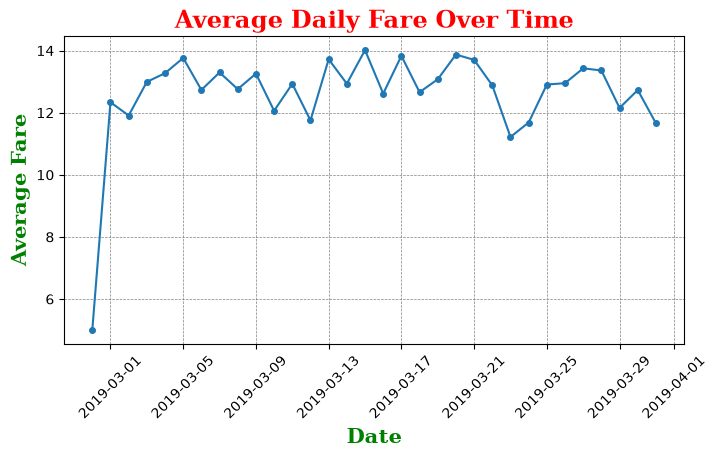

In [10]:
# pickup is in datetime format.

# Plotting the individual fares to pickup gives a crowded plot, so it is better to plot the average daily fare for each day

daily_fare = df.groupby(df['pickup'].dt.date)['fare'].mean()

font1 = {'family': 'serif', 'color': 'red', 'weight': 'bold', 'size': 17}
font2 = {'family': 'serif', 'color': 'green', 'weight': 'bold', 'size': 15}

plt.figure(figsize=(8, 4))
plt.plot(daily_fare.index, daily_fare.values, marker='o', markersize = 4, linestyle='-')
plt.xlabel('Date',fontdict=font2)
plt.ylabel('Average Fare',fontdict=font2)
plt.title('Average Daily Fare Over Time',fontdict=font1)
plt.xticks(rotation=45)
plt.grid(color = 'grey',linestyle = '--', linewidth = 0.5)
plt.show()


★ Bar Chart

Create a bar chart to show the total fare for each pickup_borough. Group the data by pickup_borough and sum the fare for each group

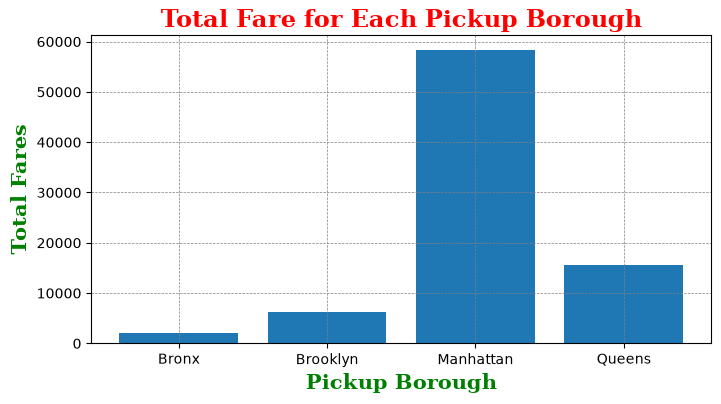

In [11]:
total_fare_borough = df.groupby('pickup_borough')['fare'].sum()

plt.figure(figsize=(8,4))
plt.bar(total_fare_borough.index, total_fare_borough.values)
plt.xlabel('Pickup Borough',fontdict=font2)
plt.ylabel('Total Fares',fontdict=font2)
plt.title('Total Fare for Each Pickup Borough',fontdict=font1)
plt.grid(color = 'grey',linestyle = '--', linewidth = 0.5)
plt.show()


★ Pie Chart

Plot a pie chart showing the distribution of trips based on the payment method (credit card, cash, etc.). Each slice should represent the count of trips for a specific payment method.

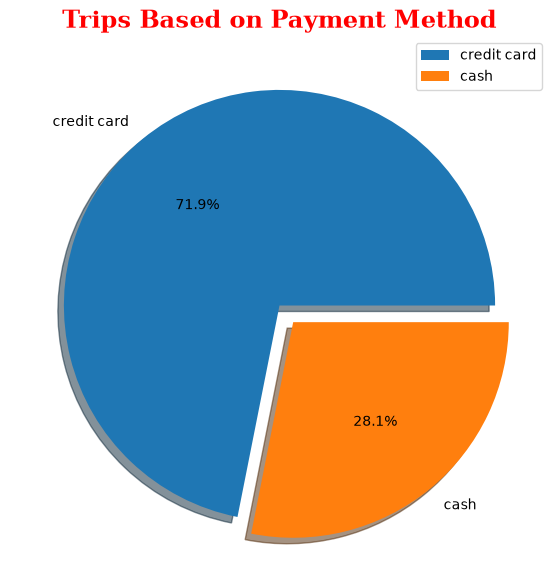

In [12]:
plt.figure(figsize=(7,7))
explod = (0,0.1)

plt.pie(df['payment'].value_counts(),labels=df['payment'].unique(),explode=explod,autopct='%1.1f%%',shadow=True)
plt.title('Trips Based on Payment Method',fontdict=font1)
plt.legend()
plt.show()

★ Histogram

Create a histogram to visualize the distribution of distance. Customize the number of bins for better granularity and ensure the plot is easy to interpret.

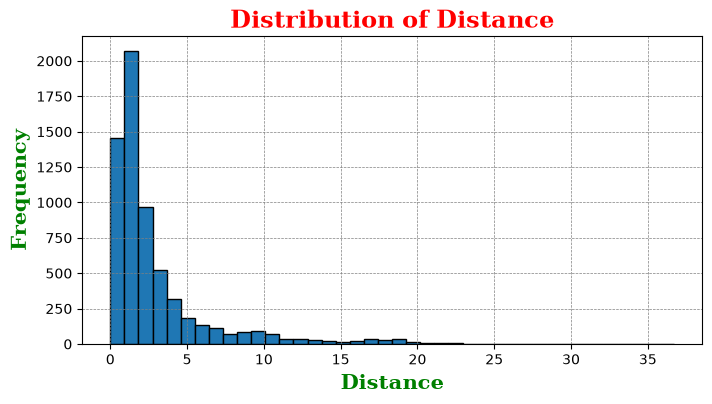

In [13]:
plt.figure(figsize=(8,4))
plt.hist(df['distance'],bins=40,edgecolor='black')
plt.xlabel('Distance',fontdict=font2)
plt.ylabel('Frequency',fontdict=font2)
plt.title('Distribution of Distance',fontdict=font1)
plt.grid(color = 'grey',linestyle = '--', linewidth = 0.5)
plt.show()

★ Box Plot

Plot a box plot to visualize the distribution of tip amounts for each pickup_borough. Use pickup_borough as the categorical axis and tip as the numeric axis.

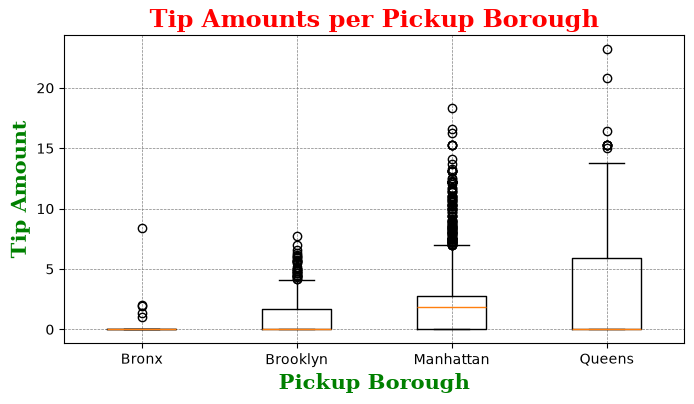

In [14]:
borough_tips = df.groupby('pickup_borough')['tip'].apply(list)

plt.figure(figsize=(8,4))
plt.boxplot(borough_tips.values,tick_labels=borough_tips.index)
plt.xlabel('Pickup Borough',fontdict=font2)
plt.ylabel('Tip Amount',fontdict=font2)
plt.title('Tip Amounts per Pickup Borough',fontdict=font1)
plt.grid(color = 'grey',linestyle = '--', linewidth = 0.5)
plt.show()

### **4) Visualizations using Seaborn:**

★ Count Plot

Create a count plot to visualize the number of trips in each pickup_borough. The x-axis should represent the boroughs, and the y-axis should show the count of trips.

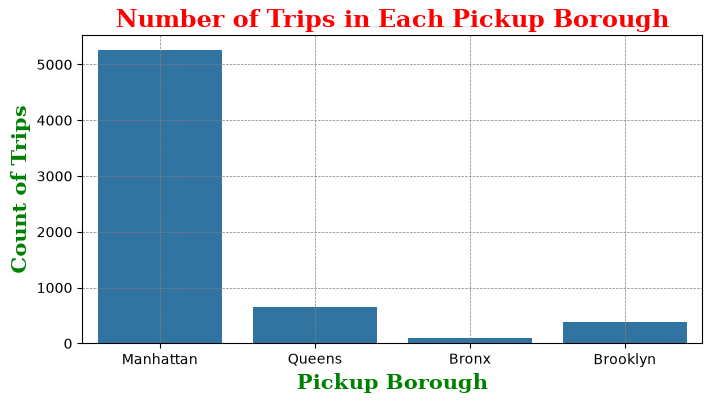

In [15]:
plt.figure(figsize=(8,4))
sns.countplot(x='pickup_borough',data=df)
plt.xlabel('Pickup Borough',fontdict=font2)
plt.ylabel('Count of Trips',fontdict=font2)
plt.title('Number of Trips in Each Pickup Borough',fontdict=font1)
plt.grid(color = 'grey',linestyle = '--', linewidth = 0.5)
plt.show()

★ Scatter Plot

Plot a scatter plot to show the relationship between distance and fare. Use
distance on the x-axis and fare on the y-axis to visualize any correlation. Color the points based on the pickup_borough to differentiate the trips by their respective boroughs.

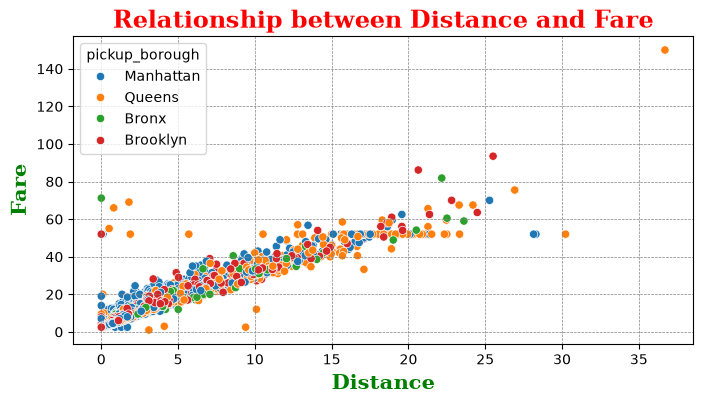

In [16]:
plt.figure(figsize=(8,4))
sns.scatterplot(x='distance',y='fare',hue='pickup_borough',data=df)
plt.xlabel('Distance',fontdict=font2)
plt.ylabel('Fare',fontdict=font2)
plt.title('Relationship between Distance and Fare',fontdict=font1)
plt.grid(color = 'grey',linestyle = '--', linewidth = 0.5)
plt.show()

★ Heatmap

Plot a heatmap to visualize the correlation between numerical variables such as
distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the
relationships.

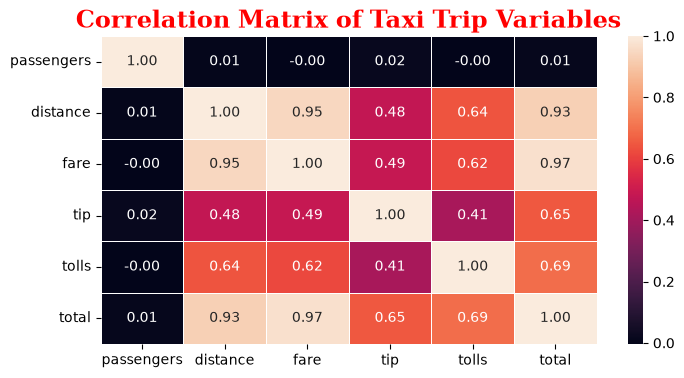

In [17]:
corr_matrix = df.select_dtypes(include='number').corr()

plt.figure(figsize=(8,4))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Taxi Trip Variables', fontdict=font1)
plt.show()

★ Pair Plot

Create a pair plot to visualize the pairwise relationships between distance, fare, tip,
and total. Color the data points according to the pickup_zone method to compare how different zones affect these variables.

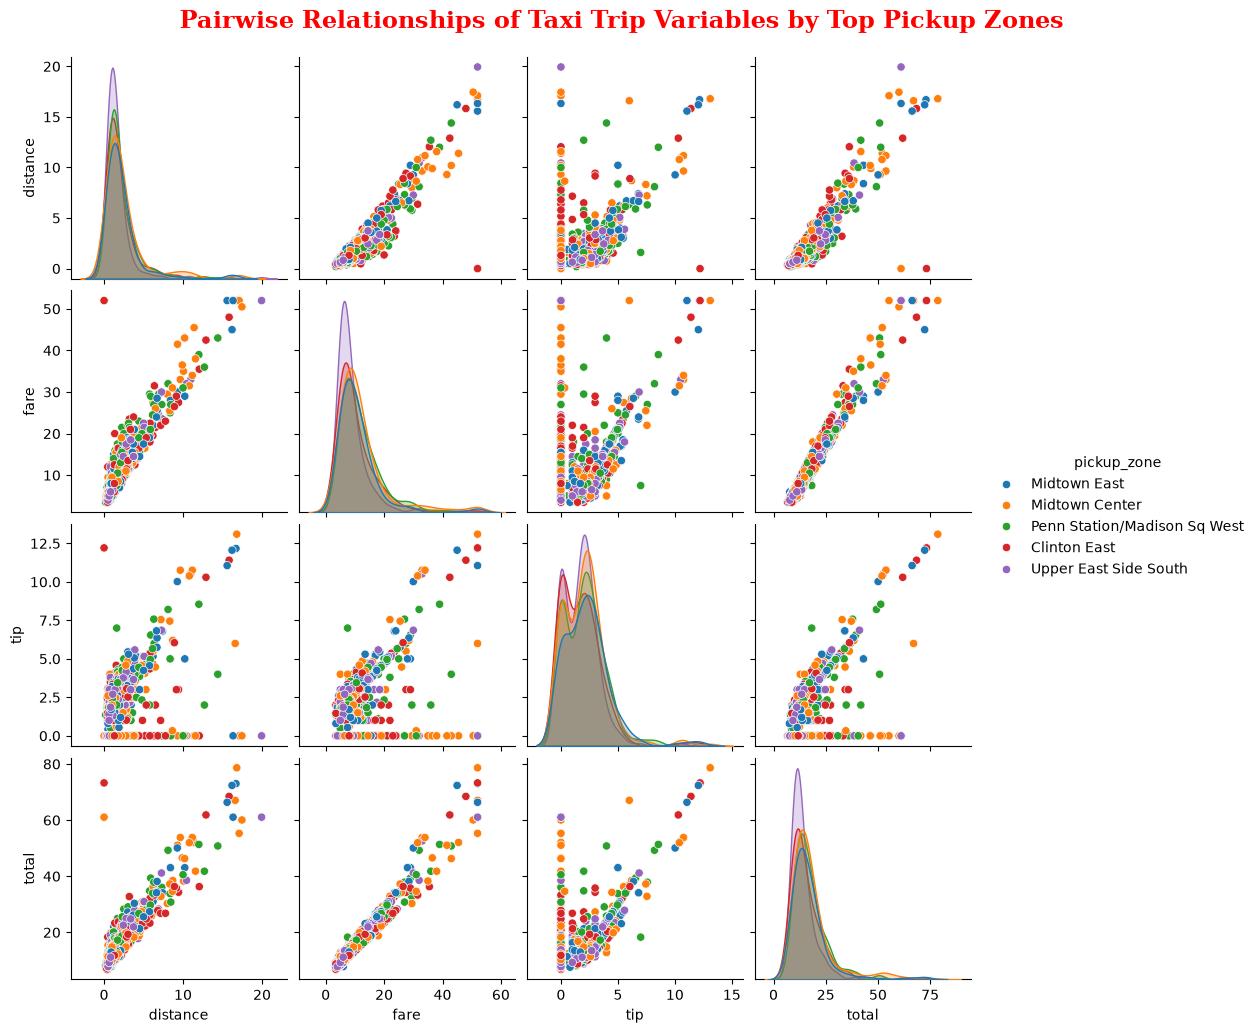

In [18]:
# Identifying the top 5 most common pickup zones for a readable legend

top_zones = df['pickup_zone'].value_counts().nlargest(5).index
filtered_df = df[df['pickup_zone'].isin(top_zones)]

# Plotting the pairplot

g = sns.pairplot(filtered_df[['distance', 'fare', 'tip', 'total', 'pickup_zone']],
    hue='pickup_zone')

# Setting the suptitle directly with explicit parameters to avoid fontdict conflicts

g.fig.suptitle('Pairwise Relationships of Taxi Trip Variables by Top Pickup Zones',
               fontsize=17, fontweight='bold', color='red', family='serif', y=1.03)

plt.show()

★ Violin Plot

Plot a violin plot to show the distribution of fare for each payment method. Use the payment method as the categorical axis and fare as the numeric axis to visualize its distribution.

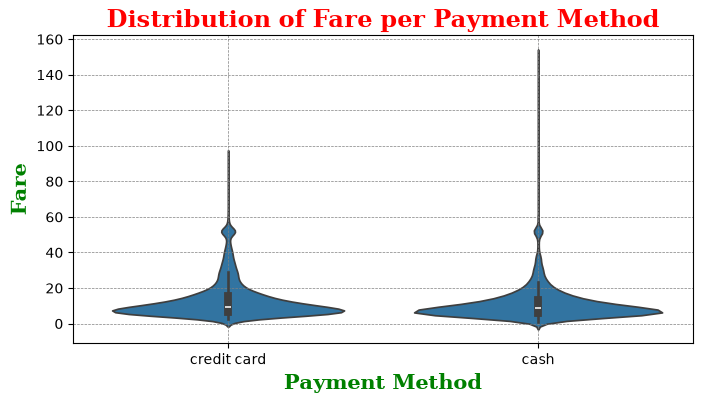

In [19]:
plt.figure(figsize=(8,4))
sns.violinplot(x='payment',y='fare',data=df)
plt.xlabel('Payment Method',fontdict=font2)
plt.ylabel('Fare',fontdict=font2)
plt.title('Distribution of Fare per Payment Method',fontdict=font1)
plt.grid(color = 'grey',linestyle = '--', linewidth = 0.5)
plt.show()